In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
root=Path("..")/"Experiment_Results"/"HasilEksperimenTahap2"/"Tahap2A"/"Population"
population_values=[50,100,250,500,1000]

dataframes=[];
for population in population_values:
    population_directory=root/str(population)
    for csv_file in population_directory.rglob("*.csv"):
        df=pd.read_csv(csv_file)
        df["population_folder"]=population
        df["source_path"]=str(csv_file.relative_to(root))

        dataframes.append(df)
if dataframes:
    df_all=pd.concat(dataframes, ignore_index=True)
else:
    df_all=pd.DataFrame()

In [3]:
df_M04=df_all[df_all["model_id"]=="M04"].copy()
summary_M04=(df_M04.groupby(["grid_rows","population", "map_type"], as_index=False).agg(
        mean_cost=("best_cost", "mean"),
        best_run=("best_cost", "min"),
        worst_run=("best_cost", "max"),
        std_cost=("best_cost", "std"),
        total_runs=("best_cost", "count")
    ))
display(summary_M04)

,grid_rows,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,50,Cluster,2.500000,2.500000,2.500000,0.000000,30
1,10,50,Maze,3.377778,3.333333,3.500000,0.074963,30
2,10,50,Random,2.601984,2.416667,2.857143,0.167405,60
3,10,100,Cluster,2.500000,2.500000,2.500000,0.000000,30
4,10,100,Maze,3.338889,3.333333,3.500000,0.030429,30
5,10,100,Random,2.596429,2.416667,2.857143,0.154454,60
6,10,250,Cluster,2.500000,2.500000,2.500000,0.000000,30
7,10,250,Maze,3.350000,3.333333,3.500000,0.050855,30
8,10,250,Random,2.573016,2.416667,2.785714,0.153765,60
9,10,500,Cluster,2.500000,2.500000,2.500000,0.000000,30


In [4]:
table_random = (
    summary_M04[summary_M04["map_type"] == "Random"]
    .sort_values("population")
)

display(table_random)
table_maze = (
    summary_M04[summary_M04["map_type"] == "Maze"]
    .sort_values("population")
)

display(table_maze)
table_cluster = (
    summary_M04[summary_M04["map_type"] == "Cluster"]
    .sort_values("population")
)

display(table_cluster)

,grid_rows,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
2,10,50,Random,2.601984,2.416667,2.857143,0.167405,60
17,20,50,Random,6.285759,6.025000,6.769231,0.216968,60
32,40,50,Random,6.721656,6.544872,7.050000,0.112038,60
20,20,100,Random,6.285865,6.025000,6.794872,0.226836,60
35,40,100,Random,6.713162,6.525641,6.929487,0.119334,60
5,10,100,Random,2.596429,2.416667,2.857143,0.154454,60
23,20,250,Random,6.259637,6.025000,6.512821,0.214709,60
8,10,250,Random,2.573016,2.416667,2.785714,0.153765,60
38,40,250,Random,6.695291,6.532051,6.893750,0.108995,60
11,10,500,Random,2.596032,2.416667,2.857143,0.159506,60


,grid_rows,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
1,10,50,Maze,3.377778,3.333333,3.500000,0.074963,30
16,20,50,Maze,6.858974,6.794872,7.025641,0.065545,30
31,40,50,Maze,6.922529,6.841379,7.075862,0.065968,30
19,20,100,Maze,6.827350,6.794872,6.897436,0.033623,30
34,40,100,Maze,6.925287,6.848276,7.103448,0.060641,30
4,10,100,Maze,3.338889,3.333333,3.500000,0.030429,30
22,20,250,Maze,6.819658,6.794872,6.871795,0.021802,30
7,10,250,Maze,3.350000,3.333333,3.500000,0.050855,30
37,40,250,Maze,6.908736,6.848276,7.110345,0.063614,30
10,10,500,Maze,3.333333,3.333333,3.333333,0.000000,30


,grid_rows,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,50,Cluster,2.500000,2.500000,2.500000,0.000000,30
15,20,50,Cluster,4.864865,4.783784,5.054054,0.068078,30
30,40,50,Cluster,5.560645,5.458065,5.800000,0.089898,30
18,20,100,Cluster,4.822523,4.783784,4.945946,0.048495,30
33,40,100,Cluster,5.574409,5.458065,5.754839,0.084976,30
3,10,100,Cluster,2.500000,2.500000,2.500000,0.000000,30
21,20,250,Cluster,4.800901,4.783784,4.918919,0.027011,30
6,10,250,Cluster,2.500000,2.500000,2.500000,0.000000,30
36,40,250,Cluster,5.518925,5.464516,5.651613,0.049096,30
9,10,500,Cluster,2.500000,2.500000,2.500000,0.000000,30


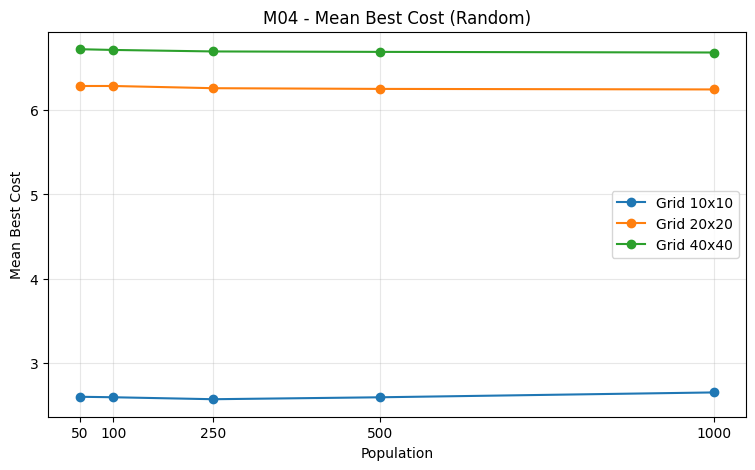

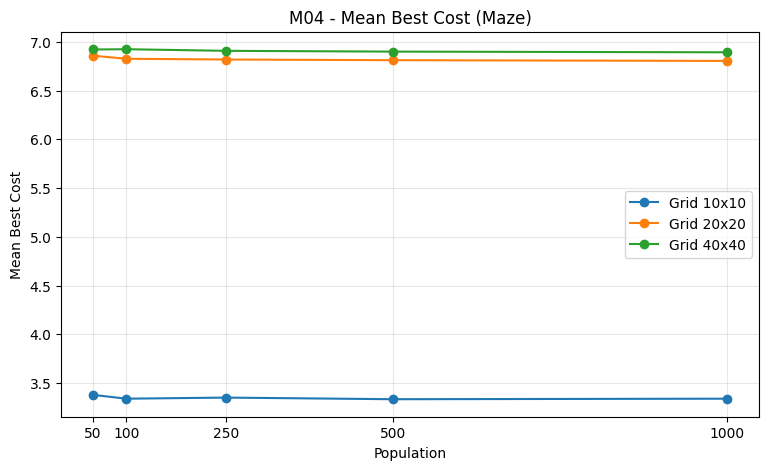

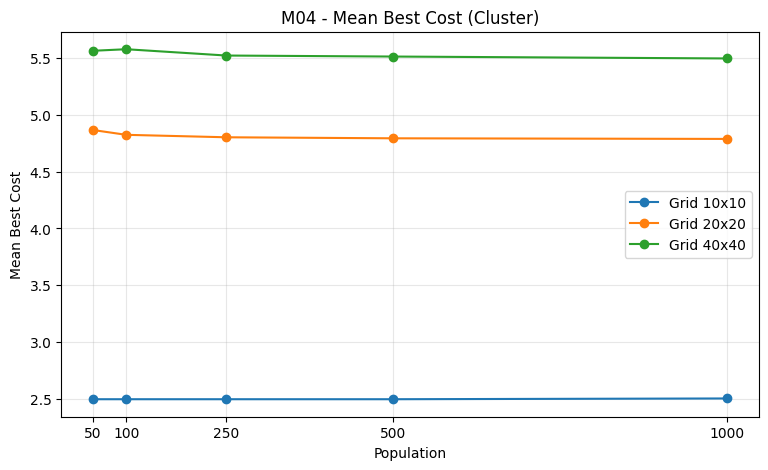

In [5]:
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = summary_M04[
        summary_M04["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("population")
        )

        plt.plot(
            data_size["population"],
            data_size["mean_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M04 - Mean Best Cost ({map_type})")
    plt.xlabel("Population")
    plt.ylabel("Mean Best Cost")
    plt.xticks(sorted(data["population"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [11]:
summary_M04["rank_mean_cost"] = (
    summary_M04
    .groupby(["grid_rows", "map_type"])["mean_cost"]
    .rank(method="average", ascending=True)
)
avg_rank_M04 = (
    summary_M04
    .groupby("population", as_index=False)
    .agg(
        avg_rank_mean=("rank_mean_cost", "mean"),
        avg_mean_cost=("mean_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_mean_cost", "count")
    )
    .sort_values(["avg_rank_mean","avg_mean_cost"])
)
display(avg_rank_M04)

,population,avg_rank_mean,avg_mean_cost,avg_std_cost,jumlah_kombinasi
3,500,1.944444,5.042921,0.070028,9
4,1000,2.055556,5.045066,0.071703,9
2,250,2.833333,5.047351,0.076650,9
1,100,3.888889,5.064879,0.084310,9
0,50,4.277778,5.077132,0.095652,9


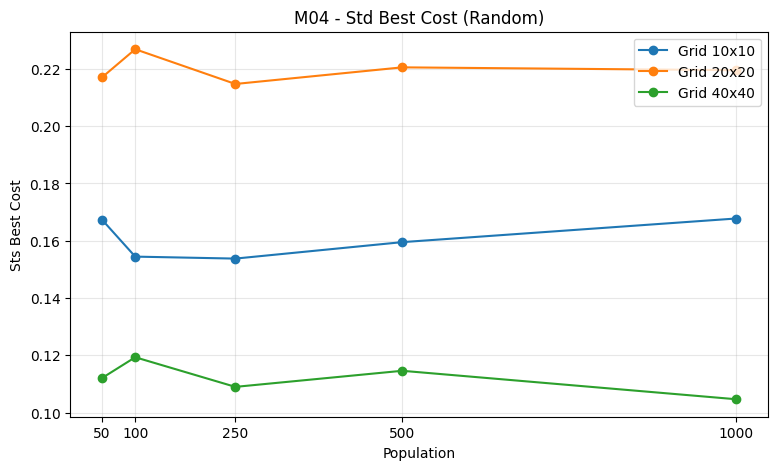

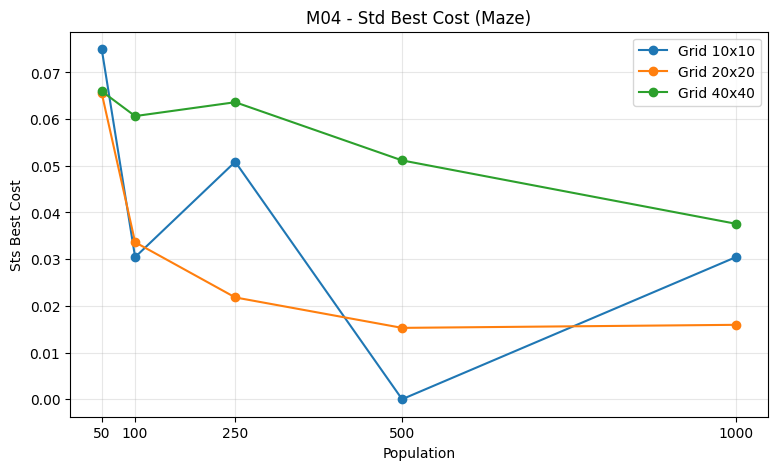

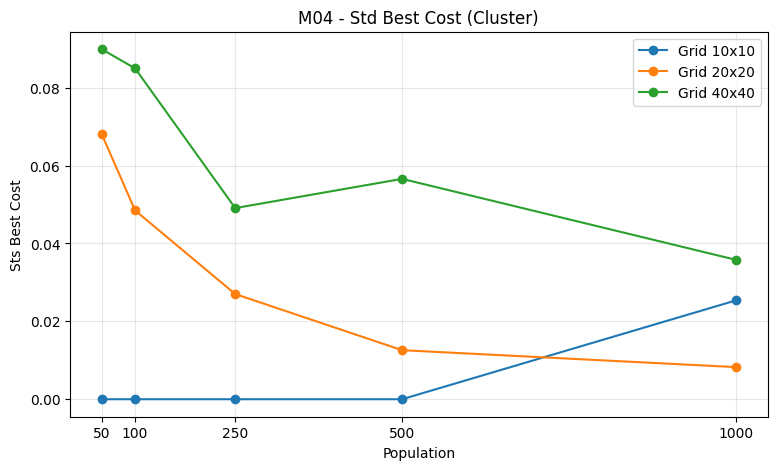

In [7]:
#std cost
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = summary_M04[
        summary_M04["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("population")
        )

        plt.plot(
            data_size["population"],
            data_size["std_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M04 - Std Best Cost ({map_type})")
    plt.xlabel("Population")
    plt.ylabel("Sts Best Cost")
    plt.xticks(sorted(data["population"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [9]:
summary_M04["rank_std_cost"] = (
    summary_M04
    .groupby(["grid_rows", "map_type"])["std_cost"]
    .rank(method="average", ascending=True)
)

avg_rank_M04_std = (
    summary_M04
    .groupby("population", as_index=False)
    .agg(
        avg_rank_std=("rank_std_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_std_cost", "count")
    )
    .sort_values([ "avg_std_cost"])
)

print(avg_rank_M04_std)

   population  avg_rank_std  avg_std_cost  jumlah_kombinasi
3         500      2.500000      0.070028                 9
4        1000      2.444444      0.071703                 9
2         250      2.500000      0.076650                 9
1         100      3.500000      0.084310                 9
0          50      4.055556      0.095652                 9
